# Base model inference

Run greedy inference with the public DeepSeek-R1-Distill-Qwen-1.5B base model over the supplied test split. The notebook downloads the model when it is not already cached, prints the available split sizes, evaluates every test row, and writes predictions, summary JSON, and interpretable plots into the Colab working directory (`/content`).

**Upload required:** `test.json`. `train.json` is optional and is used only to display its row count. No adapter is used in this baseline. If the model snapshot is not cached, internet access is needed for the Hugging Face download.


## 1. Install the inference dependencies

This cell installs the libraries needed to load the model, display progress with an ETA, and create plots.


In [1]:
!pip -q install -U transformers accelerate huggingface_hub matplotlib tqdm


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 6.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 105.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 58.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 114.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 7.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 2.2.0 which is incompatible.


## 2. Set paths, device, and reproducibility settings

Colab accepts a flat upload to `/content` or the repository folder layout. Model files are cached separately from the results.


In [2]:
import json, os, random, re, time
from collections import defaultdict
from decimal import Decimal, InvalidOperation
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from huggingface_hub import snapshot_download
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer

ROOT = Path('/content')
PACKAGE_DIR = ROOT / 'budget-force-reasoning'
BASE_DIR = ROOT / 'base'
PACKAGE_BASE_DIR = PACKAGE_DIR / 'base'
MODEL_ID = 'deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B'
MODEL_DIR = ROOT / 'base_model_weights'
OUTPUT_DIR = ROOT
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

def find_input(filename):
    # Prefer flat Colab uploads, then the repository's base/ folder.
    candidates = [ROOT / filename, BASE_DIR / filename, PACKAGE_BASE_DIR / filename, Path.cwd() / filename]
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f'Upload {filename} to /content or /content/base.')

TEST_PATH = find_input('test.json')
TRAIN_PATH = next((p for p in [ROOT/'train.json', BASE_DIR/'train.json', PACKAGE_BASE_DIR/'train.json'] if p.is_file()), None)
GPU_AVAILABLE = torch.cuda.is_available()
DEVICE = torch.device('cuda' if GPU_AVAILABLE else 'cpu')
print('Model:', MODEL_ID)
print('Test file:', TEST_PATH)
print('GPU available:', GPU_AVAILABLE)
if GPU_AVAILABLE:
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('CPU fallback selected; inference will be much slower.')


Model: deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B
Test file: /content/test.json
GPU available: True
GPU: Tesla T4


## 3. Load and validate the test data

This experiment needs only the held-out test records. The optional training file is never used for fitting or selection.


In [3]:
def load_test(path):
    rows = json.loads(path.read_text(encoding='utf-8'))
    required = {'id', 'x_i', 'y_i', 'topic'}
    if not isinstance(rows, list) or not rows:
        raise ValueError('test.json must contain a non-empty JSON array.')
    for row in rows:
        missing = required - set(row)
        if missing:
            raise ValueError(f"Record {row.get('id')} is missing fields: {sorted(missing)}")
    return rows

test_rows = load_test(TEST_PATH)
print('Train size:', len(json.loads(TRAIN_PATH.read_text(encoding='utf-8'))) if TRAIN_PATH else 'not uploaded (optional)')
print('Test size:', len(test_rows))
print('Unique test IDs:', len({row['id'] for row in test_rows}))
assert len({row['id'] for row in test_rows}) == len(test_rows), 'Duplicate IDs found in test data.'


Train size: 450
Test size: 90
Unique test IDs: 90


## 4. Download the base model if needed

The public model is cached in `/content/base_model_weights`. The notebook reports an expected download time and reuses the cache on later runs.


In [4]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
if not (MODEL_DIR / 'config.json').is_file():
    print('Downloading base model. ETA: around 5-15 minutes, depending on Colab network speed.')
    snapshot_download(repo_id=MODEL_ID, local_dir=MODEL_DIR, token=os.environ.get('HF_TOKEN'))
else:
    print('Base model is already cached; download ETA: 0 minutes.')


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

## 5. Load the tokenizer and model

The T4 uses FP16. CPU fallback uses FP32. No training or adapter weights are loaded in this baseline.


In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR, local_files_only=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
load_options = {'local_files_only': True}
if GPU_AVAILABLE:
    load_options.update(torch_dtype=torch.float16, device_map='auto')
else:
    load_options.update(torch_dtype=torch.float32)
model = AutoModelForCausalLM.from_pretrained(MODEL_DIR, **load_options)
if not GPU_AVAILABLE:
    model.to(DEVICE)
model.eval()
print('Base model loaded.')


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Base model loaded.


## 6. Define answer extraction and one greedy prediction

Every prediction receives up to 1,024 reasoning tokens plus 32 answer tokens. Greedy decoding makes comparisons repeatable.


In [6]:
THINKING_BUDGET = 1024
ANSWER_TOKENS = 32
MAX_NEW_TOKENS = THINKING_BUDGET + ANSWER_TOKENS

def canonical_number(value):
    try:
        number = Decimal(str(value).strip().replace(',', '').replace('$', ''))
    except InvalidOperation:
        return None
    if not number.is_finite():
        return None
    normalized = format(number.normalize(), 'f')
    if '.' in normalized:
        normalized = normalized.rstrip('0').rstrip('.')
    return '0' if normalized in ('', '-0') else normalized

def extract_answer(text):
    # Use the last numeric expression, which is normally the final answer.
    numbers = re.findall(r'(?<![\w.])-?\$?[\d,]+(?:\.\d+)?', text)
    return canonical_number(numbers[-1]) if numbers else None

def predict(question):
    prompt = f'Question: {question}\n\n<think>\n'
    encoded = tokenizer(prompt, return_tensors='pt').to(model.device)
    with torch.inference_mode():
        output = model.generate(**encoded, do_sample=False, max_new_tokens=MAX_NEW_TOKENS,
                                pad_token_id=tokenizer.eos_token_id,
                                eos_token_id=tokenizer.eos_token_id)
    new_tokens = output[0, encoded['input_ids'].shape[1]:]
    completion = tokenizer.decode(new_tokens, skip_special_tokens=True)
    return completion, len(new_tokens), extract_answer(completion)

print('Maximum generation allowance:', MAX_NEW_TOKENS, 'tokens per test example.')


Maximum generation allowance: 1056 tokens per test example.


## 7. Evaluate every test example

The progress bar gives a live ETA. Predictions retain the full generated trace so answers can be audited later.


In [7]:
predictions = []
started = time.time()
for row in tqdm(test_rows, desc='Base inference', unit='example'):
    completion, generated_tokens, predicted = predict(row['x_i'])
    expected = canonical_number(row['y_i'])
    predictions.append({
        'id': row['id'], 'topic': row['topic'], 'expected_answer': expected,
        'extracted_answer': predicted, 'correct': predicted == expected,
        'generated_tokens': generated_tokens, 'trace': completion,
    })
elapsed_minutes = (time.time() - started) / 60
print(f'Inference finished in {elapsed_minutes:.1f} minutes.')


Base inference:   0%|          | 0/90 [00:00<?, ?example/s]

Inference finished in 35.5 minutes.


## 8. Summarize and plot results

The charts show overall accuracy, per-topic accuracy, and generated-token use. The JSON files are saved directly under `/content` in Colab.


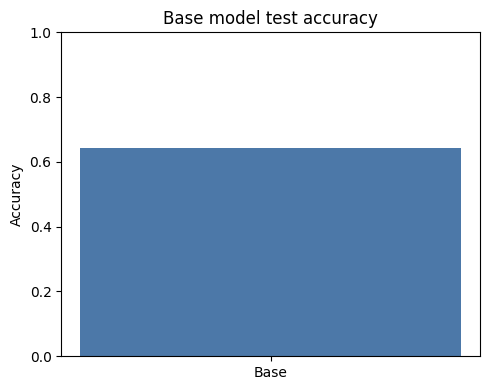

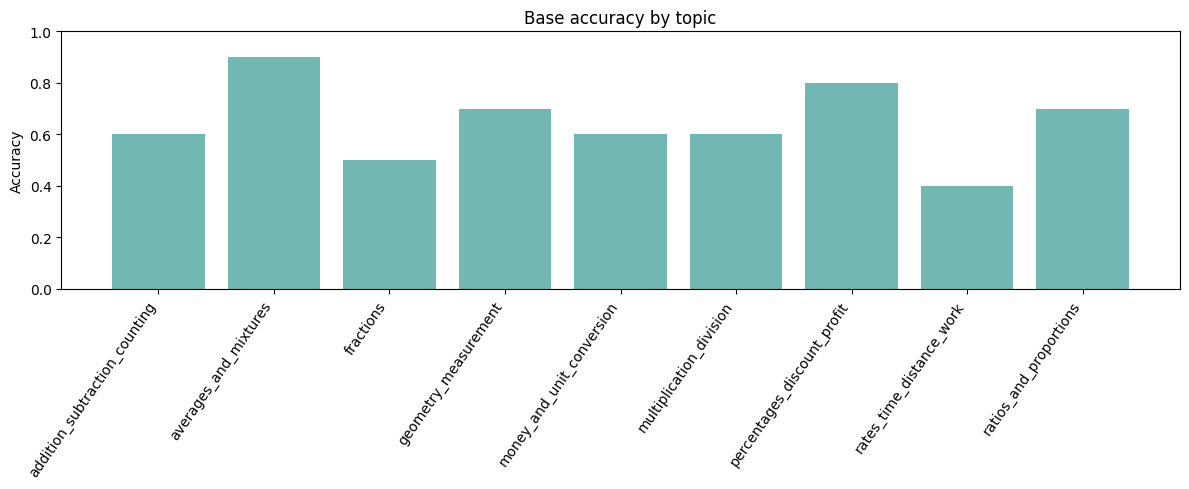

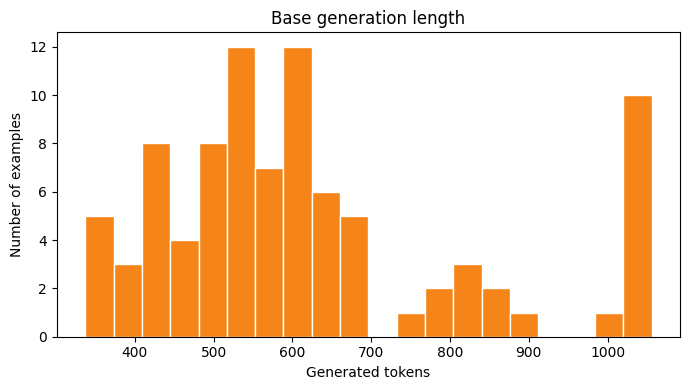

{
  "summary": {
    "model": "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
    "method": "greedy_base_inference",
    "correct": 58,
    "total": 90,
    "accuracy": 0.6444444444444445,
    "average_generated_tokens": 622.8777777777777,
    "max_new_tokens": 1056,
    "runtime_minutes": 35.537457386652626
  },
  "per_topic": {
    "addition_subtraction_counting": {
      "correct": 6,
      "total": 10,
      "accuracy": 0.6
    },
    "averages_and_mixtures": {
      "correct": 9,
      "total": 10,
      "accuracy": 0.9
    },
    "fractions": {
      "correct": 5,
      "total": 10,
      "accuracy": 0.5
    },
    "geometry_measurement": {
      "correct": 7,
      "total": 10,
      "accuracy": 0.7
    },
    "money_and_unit_conversion": {
      "correct": 6,
      "total": 10,
      "accuracy": 0.6
    },
    "multiplication_division": {
      "correct": 6,
      "total": 10,
      "accuracy": 0.6
    },
    "percentages_discount_profit": {
      "correct": 8,
      "total": 10,


In [8]:
per_topic = {}
for topic in sorted({row['topic'] for row in predictions}):
    group = [row for row in predictions if row['topic'] == topic]
    per_topic[topic] = {'correct': sum(row['correct'] for row in group),
                        'total': len(group),
                        'accuracy': sum(row['correct'] for row in group) / len(group)}
summary = {
    'model': MODEL_ID, 'method': 'greedy_base_inference',
    'correct': sum(row['correct'] for row in predictions),
    'total': len(predictions), 'accuracy': sum(row['correct'] for row in predictions) / len(predictions),
    'average_generated_tokens': sum(row['generated_tokens'] for row in predictions) / len(predictions),
    'max_new_tokens': MAX_NEW_TOKENS, 'runtime_minutes': elapsed_minutes,
}

plt.figure(figsize=(5, 4))
plt.bar(['Base'], [summary['accuracy']], color='#4C78A8')
plt.ylim(0, 1); plt.ylabel('Accuracy'); plt.title('Base model test accuracy')
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'base_accuracy.png', dpi=160); plt.show()

topics = list(per_topic)
plt.figure(figsize=(12, 5))
plt.bar(topics, [per_topic[t]['accuracy'] for t in topics], color='#72B7B2')
plt.ylim(0, 1); plt.ylabel('Accuracy'); plt.title('Base accuracy by topic')
plt.xticks(rotation=55, ha='right'); plt.tight_layout()
plt.savefig(OUTPUT_DIR/'base_per_topic_accuracy.png', dpi=160); plt.show()

plt.figure(figsize=(7, 4))
plt.hist([row['generated_tokens'] for row in predictions], bins=20, color='#F58518', edgecolor='white')
plt.xlabel('Generated tokens'); plt.ylabel('Number of examples'); plt.title('Base generation length')
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'base_generation_tokens.png', dpi=160); plt.show()

(OUTPUT_DIR/'base_predictions.json').write_text(json.dumps(predictions, ensure_ascii=False, indent=2)+'\n', encoding='utf-8')
(OUTPUT_DIR/'base_metrics.json').write_text(json.dumps({'summary': summary, 'per_topic': per_topic}, indent=2)+'\n', encoding='utf-8')
print(json.dumps({'summary': summary, 'per_topic': per_topic}, indent=2))
print('Saved predictions, metrics, and plots under', OUTPUT_DIR)
